# Inhibitory neuron types during visual learning

How do molecularly defined inhibitory neurons respond to image changes, and which cells can be followed across learning? We use the six-mouse session catalog to describe sampling, then link one familiar-image session to the mouse's post hoc HCR measurements. All activity estimates below come from that single recording.

## 1. Environment

Use the kernel from `environment.yml` (conda environment `coms`). The first local run needs network access to Allen's public metadata service and S3. Subsequent runs reuse the cached inputs.

## 2. Imports and configuration

Set the local data directory and choose an example mouse and session for the initial analysis.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve
import json
import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pynwb
import s3fs

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

# Run from the repository, its parent, or an Allen Code Ocean capsule.
roots = [Path("/data"), Path("allen_visual_learning_data"), Path("../allen_visual_learning_data")]
default_root = next((p for p in roots if (p / "Visual-Learning-SWDB").is_dir()), roots[1])
DATA_ROOT = Path(os.environ.get("ALLEN_VISUAL_LEARNING_DATA", default_root)).expanduser().resolve()
# Code Ocean mounts /data read-only.
CACHE = Path("../scratch/visual_learning_cache").resolve() if DATA_ROOT == Path("/data") else DATA_ROOT

MOUSE = 800995
SESSION_TYPE = "OPHYS_1_images_A"
print("Data root:", DATA_ROOT, "| download cache:", CACHE)

Data root: /Users/jackpapciak/Columbia/Computation_and_brain/allen_visual_learning_data | download cache: /Users/jackpapciak/Columbia/Computation_and_brain/allen_visual_learning_data


## 3. Session metadata

Query the Allen metadata service to identify the available Visual Learning sessions and organize them by mouse, session type, and learning stage.

In [2]:
from aind_data_access_api.document_db import MetadataDbClient

VISUAL_LEARNING_MICE = ["782149", "790322", "788406", "800792", "800995", "804363"]

client = MetadataDbClient(
    host="api.allenneuraldynamics.org",
    version="v2",
    database="metadata_index",
    collection="data_assets",
)

aggregate = [
    {
        "$match": {
            "data_description.subject_id": {"$in": VISUAL_LEARNING_MICE},
            "data_description.modalities.abbreviation": "pophys",
            "acquisition.acquisition_type": {"$exists": True, "$ne": "CENTER_MOUSEMOTION"},
        }
    },
    {
        "$project": {
            "name": 1,
            "subject_id": "$data_description.subject_id",
            "project_name": "$data_description.project_name",
            "acquisition_type": "$acquisition.acquisition_type",
            "session_start_time": "$acquisition.acquisition_start_time",
            "rig": "$acquisition.instrument_id",
            "planes": {
                "$reduce": {
                    "input": {
                        "$reduce": {
                            "input": "$acquisition.data_streams",
                            "initialValue": [],
                            "in": {"$concatArrays": ["$$value", {"$ifNull": ["$$this.configurations", []]}]},
                        }
                    },
                    "initialValue": [],
                    "in": {
                        "$concatArrays": [
                            "$$value",
                            {
                                "$reduce": {
                                    "input": {"$ifNull": ["$$this.images", []]},
                                    "initialValue": [],
                                    "in": {"$concatArrays": ["$$value", {"$ifNull": ["$$this.planes", []]}]},
                                }
                            },
                        ]
                    },
                }
            },
        }
    },
    {
        "$project": {
            "name": 1,
            "subject_id": 1,
            "project_name": 1,
            "acquisition_type": 1,
            "session_start_time": 1,
            "rig": 1,
            "n_planes": {"$size": "$planes"},
            "plane_indices": "$planes.plane_index",
            "imaging_depths": "$planes.depth",
            "targeted_structures": "$planes.targeted_structure.acronym",
        }
    },
    {"$match": {"n_planes": 8}},
]

catalog_cache = CACHE / "metadata" / "visual_learning_docdb_records.json"
if catalog_cache.is_file():
    records = json.loads(catalog_cache.read_text())
else:
    records = client.aggregate_docdb_records(pipeline=aggregate)
    catalog_cache.parent.mkdir(parents=True, exist_ok=True)
    catalog_cache.write_text(json.dumps(records))
sessions = pd.DataFrame(records)

processed_pattern = (
    r"^multiplane-ophys_\d+_\d{4}-\d{2}-\d{2}_[\d-]+"
    r"_processed_\d{4}-\d{2}-\d{2}_[\d-]+$"
)

sessions = sessions[sessions["name"].str.match(processed_pattern, na=False)].copy()
sessions["session_id"] = sessions["name"].str.extract(
    r"^(multiplane-ophys_\d+_\d{4}-\d{2}-\d{2}_[\d-]+)_processed_"
)
sessions["processed_stamp"] = sessions["name"].str.extract(
    r"_processed_(\d{4}-\d{2}-\d{2}_[\d-]+)$"
)

sessions = (
    sessions.sort_values("processed_stamp")
    .drop_duplicates("session_id", keep="last")
    .copy()
)

sessions["session_date"] = pd.to_datetime(sessions["session_start_time"].str[:10]).dt.date
sessions["session_type"] = sessions["acquisition_type"]
sessions["stage"] = sessions["session_type"].str.extract(r"^(TRAINING_\d|OPHYS_\d|STAGE_\d)")
sessions["image_set"] = sessions["session_type"].str.extract(r"_images_([AB])")

sessions = sessions.sort_values(["subject_id", "session_date", "session_start_time"]).reset_index(drop=True)
sessions["session_number"] = sessions.groupby("subject_id").cumcount() + 1

def ordered_plane_info(row):
    triples = sorted(
        zip(row["plane_indices"], row["targeted_structures"], row["imaging_depths"]),
        key=lambda x: x[0],
    )
    names = [f"{structure}_{idx}" for idx, structure, depth in triples]
    depths = [depth for idx, structure, depth in triples]
    return names, depths

plane_info = sessions.apply(ordered_plane_info, axis=1)
sessions["plane_names"] = [x[0] for x in plane_info]
sessions["imaging_depths"] = [x[1] for x in plane_info]

print("Unique sessions:", len(sessions))
print("Mice:", sessions["subject_id"].nunique())
display(sessions[["subject_id", "session_number", "session_date", "session_type", "stage", "image_set", "n_planes"]].head(12))

Unique sessions: 147
Mice: 6


,subject_id,session_number,session_date,session_type,stage,image_set,n_planes
0,782149,1,2025-03-25,TRAINING_0_gratings_autorewards_15min,TRAINING_0,NaN,8
1,782149,2,2025-03-28,TRAINING_1_gratings,TRAINING_1,NaN,8
2,782149,3,2025-03-29,TRAINING_1_gratings,TRAINING_1,NaN,8
3,782149,4,2025-03-31,TRAINING_1_gratings,TRAINING_1,NaN,8
4,782149,5,2025-04-01,TRAINING_2_gratings_flashed,TRAINING_2,NaN,8
5,782149,6,2025-04-02,TRAINING_3_images_A_10uL_reward,TRAINING_3,A,8
6,782149,7,2025-04-04,TRAINING_3_images_A_10uL_reward,TRAINING_3,A,8
7,782149,8,2025-04-08,TRAINING_3_images_A_10uL_reward,TRAINING_3,A,8
8,782149,9,2025-04-09,TRAINING_4_images_A_training,TRAINING_4,A,8
9,782149,10,2025-04-10,TRAINING_5_images_A_epilogue,TRAINING_5,A,8


## 4. Session overview

Summarize the available sessions across mice and learning stages.

stage,OPHYS_1,OPHYS_4,OPHYS_6,STAGE_0,STAGE_1,TRAINING_0,TRAINING_1,TRAINING_2,TRAINING_3,TRAINING_4,TRAINING_5
subject_id,,,,,,,,,,,
782149,2,2,2,1,3,1,3,1,3,2,4
788406,2,2,3,2,3,1,11,2,3,1,2
790322,2,2,2,1,4,2,3,2,3,1,2
800792,2,2,3,1,3,1,4,2,4,1,2
800995,2,2,3,1,3,1,3,1,3,1,2
804363,2,2,2,1,3,1,2,1,3,1,2


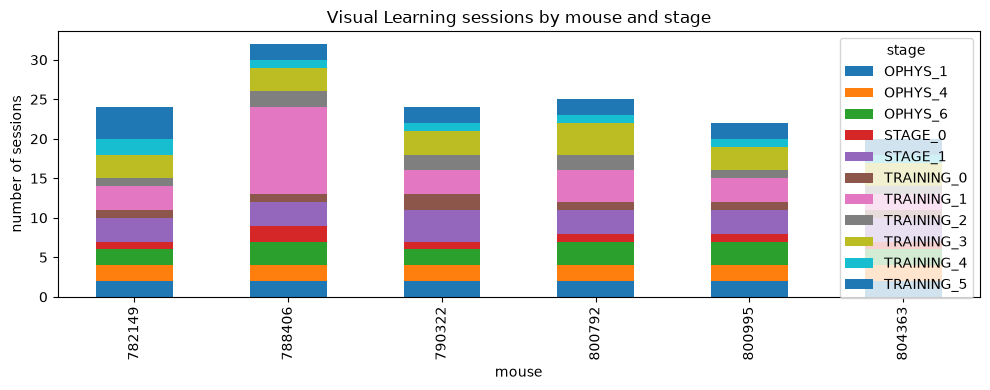

In [3]:
session_counts = sessions.groupby(["subject_id", "stage"]).size().unstack(fill_value=0)
display(session_counts)

fig, ax = plt.subplots(figsize=(10, 4))
session_counts.plot(kind="bar", stacked=True, ax=ax)
ax.set_xlabel("mouse")
ax.set_ylabel("number of sessions")
ax.set_title("Visual Learning sessions by mouse and stage")
plt.tight_layout()
plt.show()

,session_number,session_date,session_type,stage,image_set
105,1,2025-08-05,TRAINING_0_gratings_autorewards_15min,TRAINING_0,NaN
106,2,2025-08-07,TRAINING_1_gratings,TRAINING_1,NaN
107,3,2025-08-08,TRAINING_1_gratings,TRAINING_1,NaN
108,4,2025-08-11,TRAINING_1_gratings,TRAINING_1,NaN
109,5,2025-08-12,TRAINING_2_gratings_flashed,TRAINING_2,NaN
110,6,2025-08-13,TRAINING_3_images_A_10uL_reward,TRAINING_3,A
111,7,2025-08-14,TRAINING_3_images_A_10uL_reward,TRAINING_3,A
112,8,2025-08-15,TRAINING_3_images_A_10uL_reward,TRAINING_3,A
113,9,2025-08-18,TRAINING_4_images_A_training,TRAINING_4,A
114,10,2025-08-19,TRAINING_5_images_A_epilogue,TRAINING_5,A


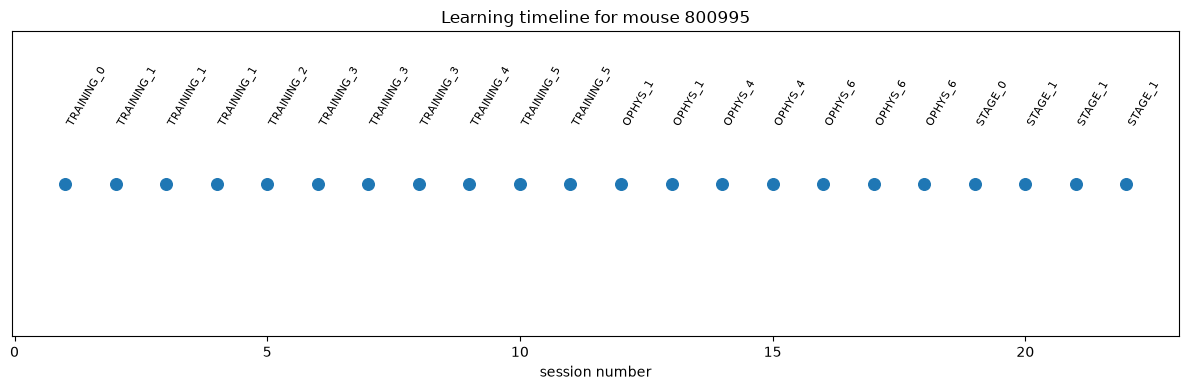

In [4]:
mouse_sessions = sessions[sessions["subject_id"].astype(str) == str(MOUSE)].sort_values("session_number").copy()
display(mouse_sessions[["session_number", "session_date", "session_type", "stage", "image_set"]])

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(mouse_sessions["session_number"], np.zeros(len(mouse_sessions)), s=70)
for _, row in mouse_sessions.iterrows():
    ax.text(row["session_number"], 0.02, row["stage"], rotation=60, ha="left", va="bottom", fontsize=8)
ax.set_yticks([])
ax.set_xlabel("session number")
ax.set_title(f"Learning timeline for mouse {MOUSE}")
plt.tight_layout()
plt.show()

## 5. Select a session

Use the first familiar-image session of mouse 800995 as the worked example. The cohort timeline gives its position in training.

In [5]:
matches = mouse_sessions[mouse_sessions["session_type"] == SESSION_TYPE]
if matches.empty:
    print("Requested session type not found. Available session types:")
    display(mouse_sessions["session_type"].value_counts())
    raise ValueError(f"No {SESSION_TYPE!r} session for mouse {MOUSE}")

session = matches.iloc[0]
session

_id                                 60dba14f-4112-4069-9552-c4dfacfa9d96
name                   multiplane-ophys_800995_2025-08-21_12-22-40_pr...
subject_id                                                        800995
project_name                                     Learning mFISH-V1omFISH
acquisition_type                                        OPHYS_1_images_A
session_start_time                      2025-08-21 12:22:40.918319-07:00
rig                                                   422_MESO2_20241017
n_planes                                                               8
plane_indices                                   [0, 1, 2, 3, 4, 5, 6, 7]
imaging_depths                    [156, 196, 118, 228, 88, 268, 26, 314]
targeted_structures     [VISp, VISp, VISp, VISp, VISp, VISp, VISp, VISp]
session_id                   multiplane-ophys_800995_2025-08-21_12-22-40
processed_stamp                                      2026-08-19_00-57-55
session_date                                       

## 6. Load the selected session

The physiology and behavioral data are stored in NWB format. The notebook works with one session at a time.

If the selected session is not already stored locally, it is downloaded from the Allen public data bucket.

In [6]:
session_name = session["name"]
nwb_filename = session["session_id"] + ".nwb.zarr"
asset_path = Path("Visual-Learning-SWDB") / session_name / nwb_filename
nwb_path = DATA_ROOT / asset_path
if not nwb_path.exists():
    nwb_path = CACHE / asset_path
    if not nwb_path.exists():
        fs = s3fs.S3FileSystem(anon=True)
        remote = f"aind-open-data/{session_name}/{nwb_filename}"
        nwb_path.parent.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=nwb_path.parent) as tmp:
            store = Path(tmp) / nwb_filename
            fs.get(remote, str(store), recursive=True)
            store.rename(nwb_path)

print("NWB store:", nwb_path)

NWB store: /Users/jackpapciak/Columbia/Computation_and_brain/allen_visual_learning_data/Visual-Learning-SWDB/multiplane-ophys_800995_2025-08-21_12-22-40_processed_2026-08-19_00-57-55/multiplane-ophys_800995_2025-08-21_12-22-40.nwb.zarr


## 7. Open the NWB data

NWB (Neurodata Without Borders) is the standardized format used to store the session's neural activity, behavior, stimuli, and metadata.

In [7]:
nwb = pynwb.read_nwb(str(nwb_path))
assert nwb.session_id == session["session_id"] and str(nwb.subject.subject_id) == str(MOUSE)
print("Session ID:", nwb.session_id)
print("Processing modules:", list(nwb.processing.keys()))
print("Interval tables:", list(nwb.intervals.keys()))
print("Event tables:", list(nwb.events.keys()) if nwb.events else [])

/Users/jackpapciak/miniconda3/envs/coms/lib/python3.11/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/jackpapciak/miniconda3/envs/coms/lib/python3.11/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/jackpapciak/miniconda3/envs/coms/lib/python3.11/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events defines a different specification for Meanin

Session ID: multiplane-ophys_800995_2025-08-21_12-22-40
Processing modules: ['VISp_0', 'VISp_1', 'VISp_2', 'VISp_3', 'VISp_4', 'VISp_5', 'VISp_6', 'VISp_7', 'running']
Interval tables: ['intervals', 'natural_movie_one_presentations', 'stimulus_presentations', 'trials']
Event tables: ['events']


## 8. Physiology overview

Summarize the imaging planes, depths, ROI counts, recording duration, and sampling rate.

In [8]:
plane_names = [name for name in nwb.processing.keys() if name.startswith("VIS")]
depth_of_plane = dict(zip(session["plane_names"], session["imaging_depths"]))

plane_summary = []
roi_frames = []
session_key = f"{MOUSE}_{session['session_date']}"
for plane in plane_names:
    dff_series = nwb.processing[plane]["dff_timeseries"]["dff_timeseries"]
    timestamps = np.asarray(dff_series.timestamps[:])
    # Each trace column points to a row in its plane's segmentation table.
    rows = np.asarray(dff_series.rois.data[:], dtype=int)
    table = dff_series.rois.table
    assert len(rows) == dff_series.data.shape[1] and len(np.unique(rows)) == len(rows)
    assert ((rows >= 0) & (rows < len(table))).all()
    is_soma = np.asarray(table["is_soma"].data[:])[rows].astype(bool)
    roi_frames.append(pd.DataFrame({
        "session_key": session_key, "plane": plane, "depth_um": depth_of_plane[plane],
        "trace_col": np.arange(len(rows)), "roi_idx": rows, "is_soma": is_soma,
        "unique_roi_id": [f"{session_key}_{plane}_{i:04d}" for i in rows],
    }))
    plane_summary.append({
        "plane": plane,
        "depth_um": depth_of_plane.get(plane, np.nan),
        "n_frames": dff_series.data.shape[0],
        "n_rois": dff_series.data.shape[1],
        "n_soma": int(is_soma.sum()),
        "frame_rate_hz": 1 / np.median(np.diff(timestamps)),
        "duration_min": (timestamps[-1] - timestamps[0]) / 60,
    })

recorded = pd.concat(roi_frames, ignore_index=True)
assert recorded.unique_roi_id.is_unique
plane_summary = pd.DataFrame(plane_summary).sort_values("depth_um")
display(plane_summary)
print("Total ROIs:", plane_summary["n_rois"].sum())
print("Total soma ROIs:", plane_summary["n_soma"].sum())

,plane,depth_um,n_frames,n_rois,n_soma,frame_rate_hz,duration_min
6,VISp_6,26,48370,59,59,10.742292,75.042100
4,VISp_4,88,48370,100,87,10.742292,75.042099
2,VISp_2,118,48370,79,74,10.742292,75.042100
0,VISp_0,156,48370,66,61,10.742292,75.042099
1,VISp_1,196,48370,61,59,10.742292,75.042099
3,VISp_3,228,48370,84,77,10.742292,75.042100
5,VISp_5,268,48370,65,57,10.742292,75.042099
7,VISp_7,314,48370,68,63,10.742292,75.042100


Total ROIs: 582
Total soma ROIs: 537


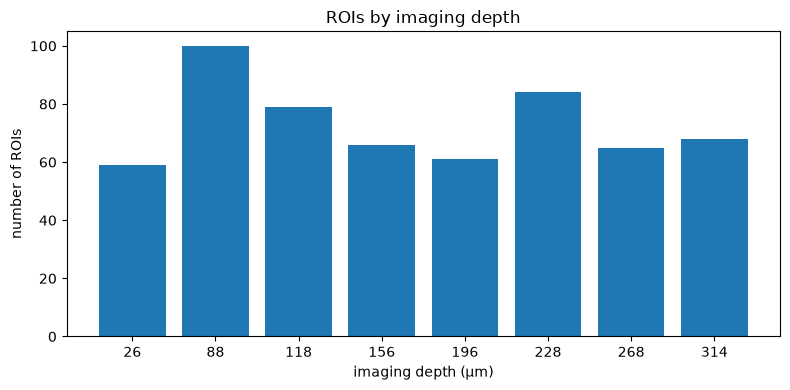

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(plane_summary["depth_um"].astype(str), plane_summary["n_rois"])
ax.set_xlabel("imaging depth (µm)")
ax.set_ylabel("number of ROIs")
ax.set_title("ROIs by imaging depth")
plt.tight_layout()
plt.show()

## 9. Calcium activity

Inspect ΔF/F activity from one imaging plane to understand the structure and range of the neural signals.

In [10]:
PLANE = plane_summary.iloc[len(plane_summary) // 2]["plane"]

dff_series = nwb.processing[PLANE]["dff_timeseries"]["dff_timeseries"]
dff = np.asarray(dff_series.data[:])
timestamps = np.asarray(dff_series.timestamps[:])

good_rois = ~np.isnan(dff).all(axis=0)
dff = dff[:, good_rois]

print("Plane:", PLANE)
print("dF/F shape:", dff.shape)
print("Time span (min):", (timestamps[-1] - timestamps[0]) / 60)
print("Median dF/F:", np.nanmedian(dff))
print("99th percentile dF/F:", np.nanpercentile(dff, 99))

Plane: VISp_1
dF/F shape: (48370, 61)
Time span (min): 75.04209949999999
Median dF/F: 0.08960901
99th percentile dF/F: 1.4049991


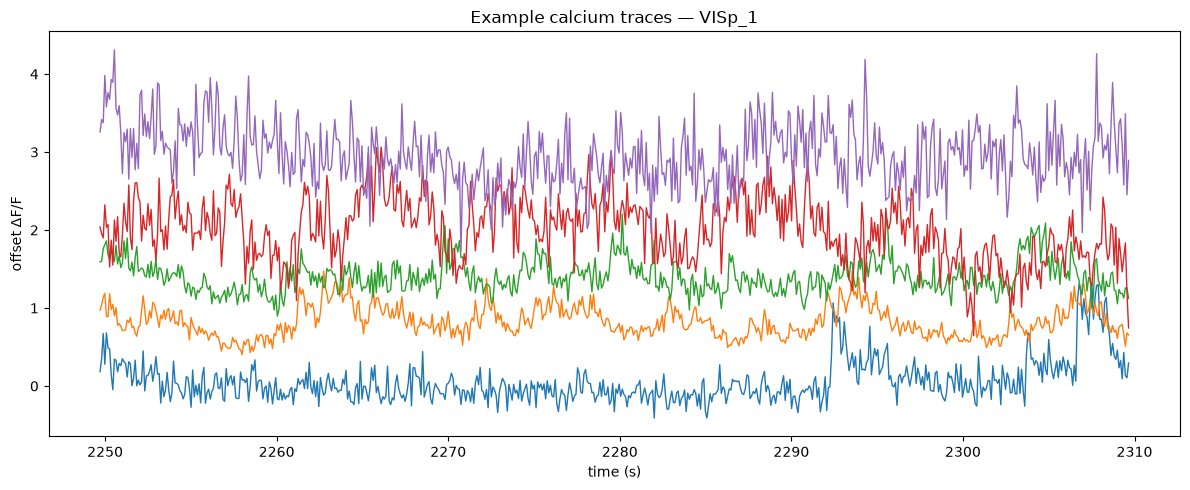

In [11]:
mid = timestamps[len(timestamps) // 2]
window = (timestamps >= mid - 30) & (timestamps <= mid + 30)

peak_scores = np.nanpercentile(dff, 99, axis=0)
example_cells = np.argsort(peak_scores)[-5:]

fig, ax = plt.subplots(figsize=(12, 5))
offset = 0
for idx in example_cells:
    trace = dff[window, idx]
    trace = trace - np.nanmedian(trace)
    ax.plot(timestamps[window], trace + offset, lw=1)
    offset += np.nanpercentile(np.abs(trace), 95) + 0.2

ax.set_xlabel("time (s)")
ax.set_ylabel("offset ΔF/F")
ax.set_title(f"Example calcium traces — {PLANE}")
plt.tight_layout()
plt.show()

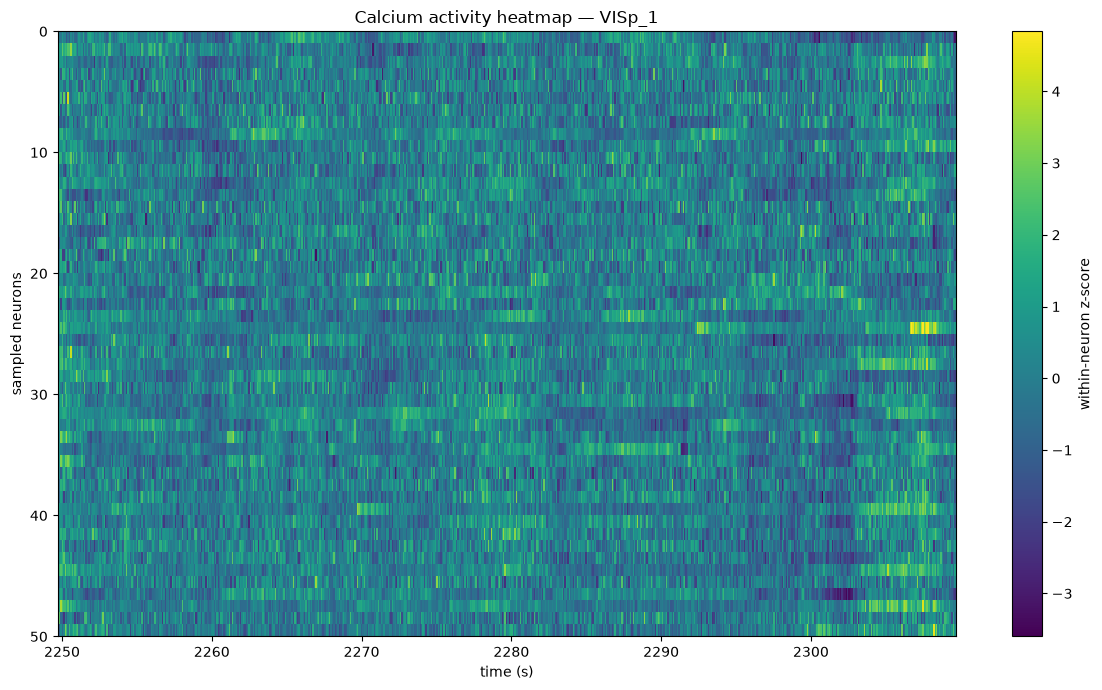

In [12]:
n_heatmap = min(50, dff.shape[1])
selected = np.linspace(0, dff.shape[1] - 1, n_heatmap, dtype=int)
heat = dff[window][:, selected].T
row_center = np.nanmedian(heat, axis=1, keepdims=True)
row_scale = np.nanstd(heat, axis=1, keepdims=True)
row_scale[row_scale == 0] = 1
heat_z = (heat - row_center) / row_scale

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(
    heat_z,
    aspect="auto",
    interpolation="nearest",
    extent=[timestamps[window][0], timestamps[window][-1], n_heatmap, 0],
)
ax.set_xlabel("time (s)")
ax.set_ylabel("sampled neurons")
ax.set_title(f"Calcium activity heatmap — {PLANE}")
fig.colorbar(im, ax=ax, label="within-neuron z-score")
plt.tight_layout()
plt.show()

## 10. Behavior

Explore running speed and trial outcomes from the selected session.

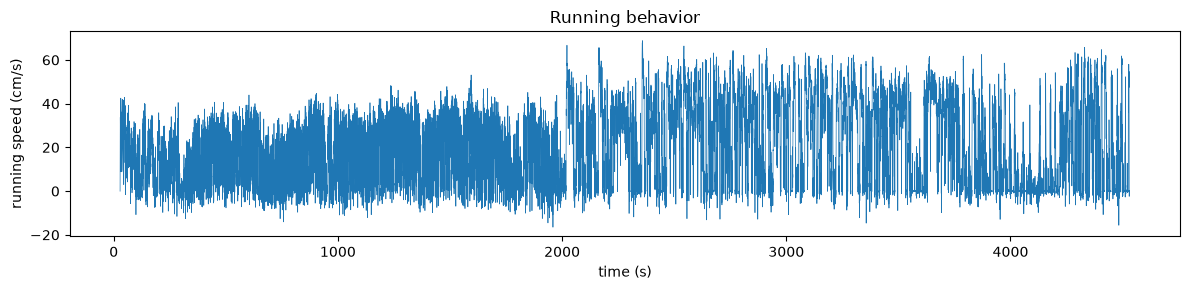

Median running speed: 19.13520214761645
95th percentile running speed: 51.4186195378729


In [13]:
if "running" in nwb.processing and "speed" in nwb.processing["running"].data_interfaces:
    speed_series = nwb.processing["running"]["speed"]
    speed = np.asarray(speed_series.data[:])
    speed_t = np.asarray(speed_series.timestamps[:])

    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(speed_t, speed, lw=0.5)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("running speed (cm/s)")
    ax.set_title("Running behavior")
    plt.tight_layout()
    plt.show()

    print("Median running speed:", np.nanmedian(speed))
    print("95th percentile running speed:", np.nanpercentile(speed, 95))
else:
    print("Running speed interface not found.")

Trials: 606


,start_time,stop_time,go,catch,auto_rewarded,aborted,hit,miss,false_alarm,correct_reject,warm_up,change_time,change_frame,initial_image_name,change_image_name,initial_orientation,change_orientation,reward_time,reward_volume,response_time,response_latency,change_window_start_time,change_window_stop_time,response_window_start_time,response_window_stop_time,epoch_name,HED
id,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,328.40371,329.88830,False,False,True,True,False,False,False,False,True,NaN,-1,im065,im065,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,change_detection,"Experimental-trial, Incorrect-action, Label/ab..."
1,329.90501,332.57384,False,False,True,True,False,False,False,False,True,NaN,-1,im065,im065,NaN,NaN,NaN,0.000,NaN,NaN,332.194643,332.573840,NaN,NaN,change_detection,"Experimental-trial, Incorrect-action, Label/ab..."
2,332.90744,342.44870,False,False,True,False,False,False,False,False,True,338.199583,18570,im065,im061,NaN,NaN,338.32861,0.005,338.94580,0.746217,335.197123,338.199583,338.349583,338.949583,change_detection,"Experimental-trial, Reward, Label/auto_rewarde..."
3,342.66555,351.42283,False,False,True,False,False,False,False,False,True,347.207103,19110,im061,im065,NaN,NaN,347.31941,0.005,347.83651,0.629407,344.955233,347.207103,347.357103,347.957103,change_detection,"Experimental-trial, Reward, Label/auto_rewarde..."
4,351.67303,352.24026,False,False,True,True,False,False,False,False,True,NaN,-1,im065,im065,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,change_detection,"Experimental-trial, Incorrect-action, Label/ab..."


,count
hit,76
miss,190
false_alarm,1
correct_reject,35
aborted,299
auto_rewarded,17


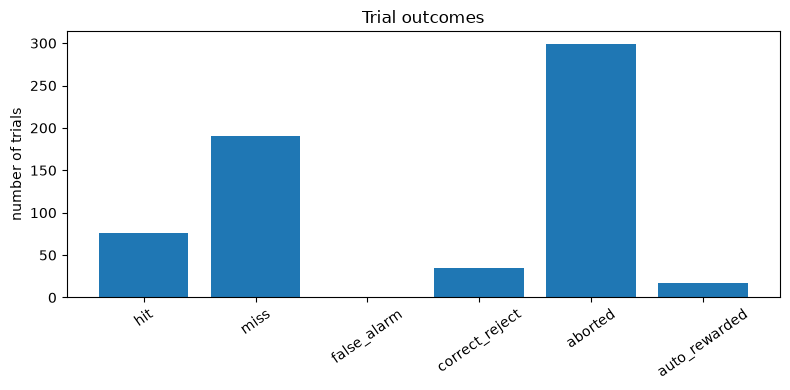

In [14]:
if "trials" in nwb.intervals:
    trials = nwb.intervals["trials"].to_dataframe()
    print("Trials:", len(trials))
    display(trials.head())

    outcome_columns = [
        c for c in ["hit", "miss", "false_alarm", "correct_reject", "aborted", "auto_rewarded"]
        if c in trials.columns
    ]
    if outcome_columns:
        outcome_counts = pd.Series({
            c: int(pd.to_numeric(trials[c], errors="coerce").fillna(0).sum())
            for c in outcome_columns
        })
        display(outcome_counts.to_frame("count"))

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.bar(outcome_counts.index, outcome_counts.values)
        ax.set_ylabel("number of trials")
        ax.set_title("Trial outcomes")
        ax.tick_params(axis="x", rotation=35)
        plt.tight_layout()
        plt.show()
else:
    print("This session has no trials table.")

## 11. Visual stimuli

Summarize image presentations, image changes, omissions, and image identities.

Stimulus presentations: 4798
Columns:
['start_time', 'stop_time', 'image_name', 'orientation', 'is_change', 'omitted', 'stimulus_presentations_id', 'trials_id', 'start_frame', 'stop_frame', 'lick_latency', 'epoch_name', 'HED']
Image changes: 271
Omitted flashes: 193


image_name
im063      620
im069      600
im066      594
im065      586
im061      572
im062      561
im085      554
im077      518
omitted    193
Name: count, dtype: int64

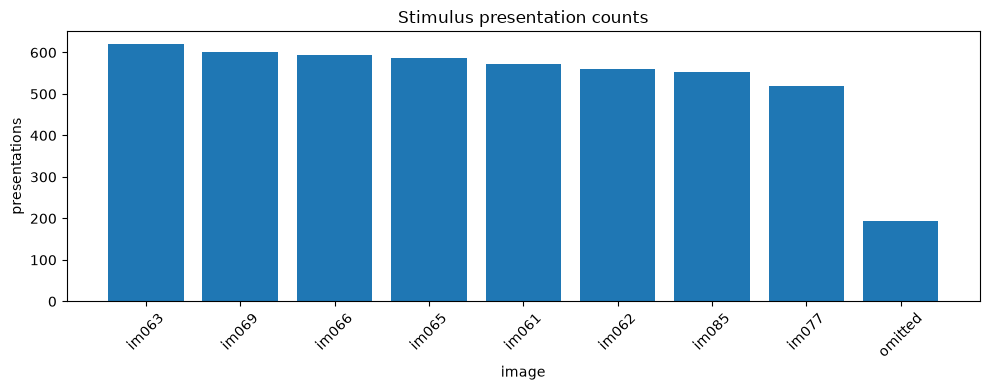

In [15]:
stim = nwb.intervals["stimulus_presentations"].to_dataframe()

print("Stimulus presentations:", len(stim))
print("Columns:")
print(stim.columns.tolist())

if "is_change" in stim:
    print("Image changes:", int(stim["is_change"].fillna(False).sum()))
if "omitted" in stim:
    print("Omitted flashes:", int(stim["omitted"].fillna(False).sum()))
if "image_name" in stim:
    image_counts = stim["image_name"].value_counts()
    display(image_counts)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(image_counts.index.astype(str), image_counts.values)
    ax.set_ylabel("presentations")
    ax.set_xlabel("image")
    ax.set_title("Stimulus presentation counts")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

## 12. Image-change aligned activity

Use the start time of each non-omitted change presentation. The stimulus table's `trials_id` links each change to an NWB trial, including its outcome and reward timing. Running speed is a separate time series on the same session clock. Align each plane on its own imaging timestamps.

,start_time,image_name,trials_id,hit,miss,auto_rewarded,reward_time
id,,,,,,,
13,338.199583,im061,2,False,False,True,338.32861
25,347.207103,im065,3,False,False,True,347.31941
53,368.224553,im085,8,False,False,True,368.33689
68,379.483903,im069,10,False,False,True,379.59622
97,401.251973,im066,16,False,False,True,401.36428


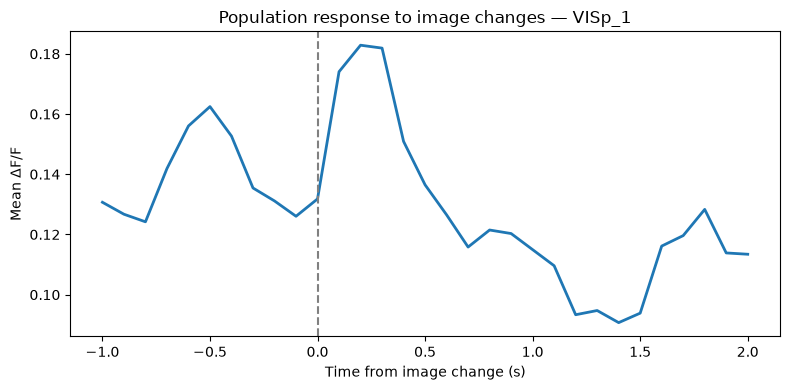

271 complete windows from 271 changes


In [16]:
changes = stim.loc[stim["is_change"] & ~stim["omitted"],
                   ["start_time", "image_name", "trials_id"]].copy()
changes = changes.join(trials[["hit", "miss", "auto_rewarded", "reward_time"]],
                       on="trials_id", validate="many_to_one")
display(changes.head())
change_times = changes["start_time"].to_numpy()
rel_t = np.arange(-10, 21) / 10  # seconds, includes an exact zero

def aligned_changes(data, time, onsets):
    """Linearly interpolate complete event windows on this plane's clock."""
    assert np.all(np.diff(time) > 0)
    samples = onsets[:, None] + rel_t
    samples = samples[(samples[:, 0] >= time[0]) & (samples[:, -1] <= time[-1])]
    right = np.searchsorted(time, samples).clip(1, len(time) - 1)
    left = right - 1
    weight = ((samples - time[left]) / (time[right] - time[left]))[:, :, None]
    return (1 - weight) * data[left] + weight * data[right]

aligned = aligned_changes(dff, timestamps, change_times)
if len(aligned):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(rel_t, np.nanmean(aligned, axis=(0, 2)), lw=2)
    ax.axvline(0, color="0.5", linestyle="--")
    ax.set(xlabel="Time from image change (s)", ylabel="Mean ΔF/F",
           title=f"Population response to image changes — {PLANE}")
    plt.tight_layout()
    plt.show()
print(f"{len(aligned)} complete windows from {len(changes)} changes")

## 13. Link the recorded ROIs to molecular identity

The Allen SWDB assets are `Visual-Learning-Coreg-Tables` (imaging-to-HCR registration) and `Visual-Learning-Cell-Gene-Tables` (per-mouse cell annotations). An attached SWDB pair can be used directly. For a local run, use the October 26 public registration release recommended by the Allen team and the matching per-mouse AnnData input listed in its provenance. Only two molecular files are needed. The printed paths identify the version used.

The public registration CSV stores `session_key`, `plane_id`, and zero-based `roi_idx`. The SWDB CSV supplies the composite `unique_roi_id` directly. Each detection may have a longitudinal `unique_roicat_id` and a resolved `hcr_id`. They occur on the same row. A direct HCR match can exist even when the track ID is missing. HCR cell IDs and ROICaT tracks are scoped to a mouse. [SWDB identifier guide](https://allenswdb.github.io/physiology/ophys/visual-learning/Tutorial-VisualLearning-Physiology-and-CellTypes.html) · [Allen release note](https://community.brain-map.org/t/visual-learning-ophys-z-drift-qc-for-early-training-3-sessions-and-public-release-of-the-2026-09-19-coreg-id-mapping-generation/5087/4) · [Release input provenance](https://aind-open-data.s3.us-west-2.amazonaws.com/cell-types-and-learning-data/consensus-clustering/hcr-inhibitory-consensus-clusters_2026-10-26_01-51-27/input_provenance.csv)

In [17]:
coreg_dir = "Visual-Learning-Coreg-Tables"
gene_dir = "Visual-Learning-Cell-Gene-Tables"
h5_name = f"{MOUSE}_cellxgene_annotated.h5ad"
mounted_coreg = sorted((DATA_ROOT / coreg_dir).glob(f"*/{MOUSE}_coreg_id_mapping_table.csv"))
mounted_h5 = sorted((DATA_ROOT / gene_dir).glob(f"*/{h5_name}"))

bucket_url = "https://aind-open-data.s3.us-west-2.amazonaws.com"
release = "hcr-inhibitory-consensus-clusters_2026-10-26_01-51-27"
release_prefix = f"cell-types-and-learning-data/consensus-clustering/{release}"

def cached_object(key, asset_dir):
    relative = Path(asset_dir) / Path(key).parent.name / Path(key).name
    for root in (DATA_ROOT, CACHE):
        if (root / relative).is_file():
            return root / relative
    path = CACHE / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=path.parent) as tmp:
        download = Path(tmp) / path.name
        urlretrieve(f"{bucket_url}/{key}", download)
        download.replace(path)
    return path

if mounted_coreg and mounted_h5:
    # Ambiguous versions require an explicit choice of data root.
    (coreg_path,), (h5_path,) = mounted_coreg, mounted_h5
else:
    coreg_path = cached_object(f"{release_prefix}/coreg_mapping_table.csv", coreg_dir)
    provenance = pd.read_csv(cached_object(f"{release_prefix}/input_provenance.csv", coreg_dir))
    gene_asset = provenance.loc[provenance["mount"].eq(f"cellxgene_{MOUSE}"), "asset_name"].item()
    h5_path = cached_object(f"{gene_asset}/{h5_name}", gene_dir)

coreg = pd.read_csv(coreg_path)
print(coreg_path, coreg.shape, coreg.columns.tolist(), sep="\n")
adata = ad.read_h5ad(h5_path, backed="r")
print(h5_path, adata.shape, f"obs index: {adata.obs_names.name}", adata.obs.columns.tolist(), sep="\n")
assert adata.obs_names.name == "cell_id"
labels = adata.obs[["class", "subclass", "cluster"]].astype("string").copy()
labels.index = pd.Index(pd.to_numeric(adata.obs_names), dtype="Int64", name="hcr_id")
adata.file.close()
assert labels.index.is_unique and labels.index.notna().all()
print("AnnData subclass values:", labels["subclass"].value_counts(dropna=False).to_dict())
labels[["subclass", "cluster"]] = labels[["subclass", "cluster"]].replace(
    {"none": pd.NA, "unassigned": pd.NA})

/Users/jackpapciak/Columbia/Computation_and_brain/allen_visual_learning_data/Visual-Learning-Coreg-Tables/hcr-inhibitory-consensus-clusters_2026-10-26_01-51-27/coreg_mapping_table.csv
(87535, 11)
['subject_id', 'session_key', 'session_name', 'plane_id', 'roi_idx', 'unique_roicat_id', 'cz_stack_id', 'resolved_cz_stack_id', 'max_iou', 'n_identities', 'hcr_id']
/Users/jackpapciak/Columbia/Computation_and_brain/allen_visual_learning_data/Visual-Learning-Cell-Gene-Tables/HCR_800995_unmixed-calibrated_2026-09-22_18-47-34/800995_cellxgene_annotated.h5ad
(118561, 27)
obs index: cell_id
['class', 'subclass', 'cluster', 'cluster_id', 'p_inhibitory', 'total_counts', 'n_genes', 'Slc17a7_counts', 'Gad2_counts']
AnnData subclass values: {'none': 108102, 'Pvalb': 3532, 'Sst': 2978, 'Lamp5': 1702, 'Vip': 1521, 'unassigned': 485, 'Sncg': 241}


In [18]:
if "unique_roi_id" not in coreg:
    coreg["unique_roi_id"] = (coreg["session_key"] + "_" + coreg["plane_id"] + "_" +
                              coreg["roi_idx"].astype(str).str.zfill(4))
key_mouse = coreg["session_key"].str.split("_").str[0]
if "subject_id" in coreg:
    assert coreg["subject_id"].astype(str).eq(key_mouse).all()
coreg["subject_id"] = key_mouse
coreg["session_id"] = coreg["session_name"].str.split("_processed_").str[0]
coreg["hcr_id"] = coreg["hcr_id"].astype("Int64").mask(coreg["hcr_id"].eq(-1))
assert coreg["unique_roi_id"].is_unique
assert coreg["hcr_id"].dropna().ge(0).all()
this_map = coreg.loc[coreg["session_id"].eq(nwb.session_id)]
if this_map.empty:
    raise ValueError(f"No registration rows for {nwb.session_id} in {coreg_path.name}")
assert this_map["session_key"].eq(session_key).all()
assert this_map["unique_roi_id"].isin(recorded["unique_roi_id"]).all()

keys = ["unique_roi_id", "unique_roicat_id", "hcr_id", "resolved_cz_stack_id"]
rois = recorded.merge(this_map[keys], on="unique_roi_id", how="left",
                      validate="one_to_one", indicator="mapping_join")
rois = rois.join(labels, on="hcr_id", validate="many_to_one")
rois["in_map"] = rois["mapping_join"].eq("both")
rois["has_hcr_row"] = rois["hcr_id"].isin(labels.index)
rois["is_typed"] = rois["class"].eq("inhibitory").fillna(False) & rois["subclass"].notna()
assert len(rois) == plane_summary["n_rois"].sum()
display(rois.loc[rois["is_typed"], ["session_key", "plane", "trace_col", "roi_idx", *keys,
                                     "class", "subclass", "cluster"]].head())

mouse_links = coreg.loc[coreg["subject_id"].eq(str(MOUSE))].dropna(subset=["hcr_id", "unique_roicat_id"])
print("Tracks linked to multiple HCR IDs across this mouse's sessions:",
      mouse_links.groupby("unique_roicat_id")["hcr_id"].nunique().gt(1).sum())
print("HCR IDs linked to multiple tracks across sessions:",
      mouse_links.groupby("hcr_id")["unique_roicat_id"].nunique().gt(1).sum())
print("Session ROIs with an HCR row and no track:", (rois.has_hcr_row & rois.unique_roicat_id.isna()).sum())

,session_key,plane,trace_col,roi_idx,unique_roi_id,unique_roicat_id,hcr_id,resolved_cz_stack_id,class,subclass,cluster
2,800995_2025-08-21,VISp_0,2,2,800995_2025-08-21_VISp_0_0002,VISp_0_0137,46766,397,inhibitory,Lamp5,Lamp5-2 Npy
5,800995_2025-08-21,VISp_0,5,5,800995_2025-08-21_VISp_0_0005,VISp_0_0144,40007,367,inhibitory,Sncg,Vip-4 Calb2/Pthlh
6,800995_2025-08-21,VISp_0,6,6,800995_2025-08-21_VISp_0_0006,VISp_0_0115,29855,352,inhibitory,Lamp5,Lamp5-2 Npy
7,800995_2025-08-21,VISp_0,7,7,800995_2025-08-21_VISp_0_0007,VISp_0_0143,35811,362,inhibitory,Lamp5,Lamp5-2 Npy
8,800995_2025-08-21,VISp_0,8,8,800995_2025-08-21_VISp_0_0008,VISp_0_0004,40374,390,inhibitory,Vip,Vip-4 Calb2/Pthlh


Tracks linked to multiple HCR IDs across this mouse's sessions: 0
HCR IDs linked to multiple tracks across sessions: 57
Session ROIs with an HCR row and no track: 8


## 14. Match coverage and cell-type composition

A recorded soma ROI is the observable unit before registration. Multiple ROIs can resolve to one HCR cell, so the tables report detection counts and distinct molecular cells separately. Percentages in each coverage column use the full recorded population named in its heading.

AnnData supplies independent `class`, `subclass`, and `cluster` columns. A cluster name can begin with a different marker than the subclass call. The subclass comparisons use the explicit subclass field.

All trace ROIs               Soma ROIs              
                                       n % of recorded         n % of recorded
Recorded                             582         100.0       537         100.0
Registration row                     582         100.0       537         100.0
ROICaT track                         557          95.7       519          96.6
Assigned HCR ID                      347          59.6       332          61.8
Matched AnnData row                  347          59.6       332          61.8
Named inhibitory subclass            301          51.7       287          53.4

soma_rois  distinct_hcr_cells
class      subclass                               
ambiguous  <NA>             22                  20
excitatory <NA>             21                  20
inhibitory Lamp5            59                  59
           Pvalb           101                  99
           Sncg              8                   8
           Sst              20                  20
           Vip              99                  86
           <NA>              2                   2
<NA>       <NA>            205                   0

soma_rois  distinct_hcr_cells
subclass cluster                                                
Lamp5    Lamp5-1  Chat/Pthlh/Ndnf          3                   3
         Lamp5-2  Npy                     31                  31
         Lamp5-3  Ndnf/Reln               10                  10
         Lamp5-4  Reln/Ndnf                8                   8
         Pvalb-2  Mme                      2                   2
         Pvalb-3  Tac1/Mme                 3                   3
         Sncg-1  Cck                       1                   1
         Sst-5  Crh                        1                   1
Pvalb    Lamp5-1  Chat/Pthlh/Ndnf          5                   5
         Pvalb-1  Pthlh                   58                  57
         Pvalb-2  Mme                     26                  26
         Pvalb-3  Tac1/Mme                12                  11
Sncg     Lamp5-3  Ndnf/Reln                2                   2
         Lamp5-4  Reln/Ndnf                3                   3
         Sst-5  Crh                        2                   2
         Vip-4  Calb2/Pthlh                1                   1
Sst      Sst-1  Reln                       4                   4
         Sst-2                             3                   3
         Sst-3  Hpse/Reln                  8                   8
         Sst-4  Calb2                      5                   5
Vip      Sncg-1  Cck                       4                   4
         Sst-5  Crh                        1                   1
         Vip-1  Crh                       33                  27
         Vip-2  Pthlh                     33                  29
         Vip-3  Chat/Calb2                19                  18
         Vip-4  Calb2/Pthlh                9                   7

recorded_rois  matched_rois  matched_pct
depth_um is_soma                                          
26       True                59            34         57.6
88       False               13             5         38.5
         True                87            51         58.6
118      False                5             2         40.0
         True                74            57         77.0
156      False                5             2         40.0
         True                61            35         57.4
196      False                2             0          0.0
         True                59            28         47.5
228      False                7             2         28.6
         True                77            53         68.8
268      False                8             4         50.0
         True                57            39         68.4
314      False                5             0          0.0
         True                63            35         55.6

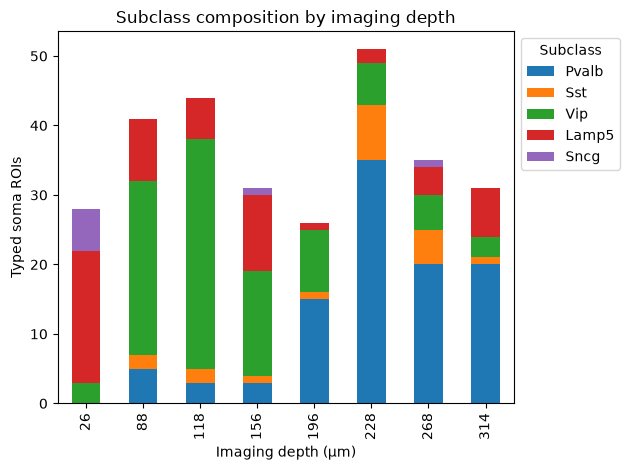

In [19]:
def coverage(frame):
    counts = pd.Series({
        "Recorded": len(frame),
        "Registration row": frame.in_map.sum(),
        "ROICaT track": frame.unique_roicat_id.notna().sum(),
        "Assigned HCR ID": frame.hcr_id.notna().sum(),
        "Matched AnnData row": frame.has_hcr_row.sum(),
        "Named inhibitory subclass": frame.is_typed.sum(),
    })
    return pd.DataFrame({"n": counts, "% of recorded": (100 * counts / len(frame)).round(1)})

somas = rois.loc[rois.is_soma].copy()
display(pd.concat({"All trace ROIs": coverage(rois), "Soma ROIs": coverage(somas)}, axis=1))
display(somas.groupby(["class", "subclass"], dropna=False).agg(
    soma_rois=("unique_roi_id", "size"), distinct_hcr_cells=("hcr_id", "nunique")))

typed = somas.loc[somas.is_typed].copy()
focus = ["Pvalb", "Sst", "Vip", "Lamp5"]
order = focus + sorted(set(typed.subclass) - set(focus))
display(typed.groupby(["subclass", "cluster"], dropna=False).agg(
    soma_rois=("unique_roi_id", "size"), distinct_hcr_cells=("hcr_id", "nunique")))
depth_coverage = rois.groupby(["depth_um", "is_soma"]).agg(
    recorded_rois=("unique_roi_id", "size"), matched_rois=("has_hcr_row", "sum"),
    matched_pct=("has_hcr_row", "mean"))
depth_coverage["matched_pct"] = (100 * depth_coverage["matched_pct"]).round(1)
display(depth_coverage)
ax = pd.crosstab(typed.depth_um, typed.subclass).reindex(
    index=sorted(rois.depth_um.unique()), columns=order, fill_value=0).plot.bar(stacked=True)
ax.set(xlabel="Imaging depth (µm)", ylabel="Typed soma ROIs", title="Subclass composition by imaging depth")
ax.legend(title="Subclass", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 15. Sampling across mice and learning stages

The registration table covers additional days without loading their calcium data. Count ROI detections per acquisition and distinct HCR cells within each mouse or stage. A cell can contribute to several stage totals. Coverage here is conditional on a row in the registration file. The NWB denominator is known only for the selected recording.

An empty entry in the session-level table indicates that the catalog acquisition has no registration rows. “Outside session catalog” identifies registered acquisitions absent from the eight-plane metadata query.

In [20]:
catalog = sessions[["subject_id", "session_id", "session_date", "session_number", "session_type", "stage"]]
registered_sessions = coreg.groupby(["subject_id", "session_id"]).agg(
    registration_rows=("unique_roi_id", "size"), hcr_matched_rois=("hcr_id", "count"),
    distinct_hcr_cells=("hcr_id", "nunique")).reset_index()
session_coverage = catalog.merge(registered_sessions, how="left", validate="one_to_one",
                                 on=["subject_id", "session_id"])
session_coverage["hcr_pct_of_rows"] = (100 * session_coverage.hcr_matched_rois /
                                        session_coverage.registration_rows).round(1)
display(session_coverage.loc[session_coverage.subject_id.eq(str(MOUSE))].drop(columns=["subject_id", "session_id"]))
stage_map = coreg.merge(catalog, on=["subject_id", "session_id"], how="left", validate="many_to_one")
stage_map["stage"] = stage_map["stage"].fillna("Outside session catalog")
stage_counts = stage_map.groupby(["subject_id", "stage"], dropna=False).agg(
    mapped_sessions=("session_id", "nunique"), roi_detections=("unique_roi_id", "size"),
    distinct_tracks=("unique_roicat_id", "nunique"), distinct_hcr_cells=("hcr_id", "nunique"))
display(stage_counts["distinct_hcr_cells"].unstack().rename_axis(columns="Stage · distinct HCR cells"))
display(stage_map.groupby("subject_id").agg(mapped_sessions=("session_id", "nunique"),
        roi_detections=("unique_roi_id", "size"), distinct_tracks=("unique_roicat_id", "nunique"),
        distinct_hcr_cells=("hcr_id", "nunique")))
# Distinct molecular cells represented in each stage of this mouse (registration metadata only).
mouse_stage = stage_map.loc[stage_map.subject_id.eq(str(MOUSE))].join(labels, on="hcr_id", validate="many_to_one")
display(mouse_stage.loc[mouse_stage["class"].eq("inhibitory")].pivot_table(
    index="stage", columns="subclass", values="hcr_id", aggfunc="nunique", fill_value=0
).reindex(columns=order, fill_value=0).rename_axis(columns="Subclass · distinct HCR cells"))

,session_date,session_number,session_type,stage,registration_rows,hcr_matched_rois,distinct_hcr_cells,hcr_pct_of_rows
105,2025-08-05,1,TRAINING_0_gratings_autorewards_15min,TRAINING_0,568.0,322,305.0,56.7
106,2025-08-07,2,TRAINING_1_gratings,TRAINING_1,575.0,307,290.0,53.4
107,2025-08-08,3,TRAINING_1_gratings,TRAINING_1,532.0,296,283.0,55.6
108,2025-08-11,4,TRAINING_1_gratings,TRAINING_1,562.0,338,318.0,60.1
109,2025-08-12,5,TRAINING_2_gratings_flashed,TRAINING_2,631.0,355,330.0,56.3
110,2025-08-13,6,TRAINING_3_images_A_10uL_reward,TRAINING_3,548.0,342,319.0,62.4
111,2025-08-14,7,TRAINING_3_images_A_10uL_reward,TRAINING_3,571.0,343,314.0,60.1
112,2025-08-15,8,TRAINING_3_images_A_10uL_reward,TRAINING_3,553.0,337,317.0,60.9
113,2025-08-18,9,TRAINING_4_images_A_training,TRAINING_4,686.0,332,306.0,48.4
114,2025-08-19,10,TRAINING_5_images_A_epilogue,TRAINING_5,561.0,351,321.0,62.6


Stage · distinct HCR cells,OPHYS_1,OPHYS_4,OPHYS_6,Outside session catalog,STAGE_0,STAGE_1,TRAINING_0,TRAINING_1,TRAINING_2,TRAINING_3,TRAINING_4,TRAINING_5
subject_id,,,,,,,,,,,,
782149,200.0,186.0,191.0,NaN,169.0,202.0,NaN,193.0,170.0,192.0,190.0,206.0
788406,444.0,427.0,463.0,NaN,438.0,443.0,314.0,502.0,419.0,432.0,401.0,413.0
790322,342.0,387.0,384.0,NaN,397.0,479.0,342.0,435.0,411.0,480.0,350.0,464.0
800792,298.0,307.0,319.0,NaN,278.0,306.0,252.0,314.0,280.0,330.0,280.0,300.0
800995,343.0,363.0,401.0,322.0,330.0,335.0,305.0,362.0,330.0,360.0,306.0,362.0
804363,386.0,418.0,409.0,346.0,385.0,406.0,359.0,390.0,363.0,412.0,337.0,394.0


,mapped_sessions,roi_detections,distinct_tracks,distinct_hcr_cells
subject_id,,,,
782149,22,15300,1196,224
788406,32,19002,1202,535
790322,22,11859,977,518
800792,25,14346,1082,348
800995,23,13253,1058,420
804363,22,13775,1121,463


Subclass · distinct HCR cells,Pvalb,Sst,Vip,Lamp5,Sncg
stage,,,,,
OPHYS_1,109,22,91,65,8
OPHYS_4,115,20,95,70,8
OPHYS_6,129,30,99,76,10
Outside session catalog,99,23,85,57,8
STAGE_0,103,15,90,64,6
STAGE_1,104,24,85,64,8
TRAINING_0,95,19,89,53,8
TRAINING_1,118,24,91,66,9
TRAINING_2,101,19,92,62,8


In [21]:
# Off-diagonal entries count inhibitory HCR cells observed in both stages.
presence = (mouse_stage.loc[mouse_stage["class"].eq("inhibitory") & mouse_stage["subclass"].notna()
                           & mouse_stage.stage.isin(["OPHYS_1", "OPHYS_4", "OPHYS_6"])]
            .groupby(["hcr_id", "stage"]).size().unstack(fill_value=0).gt(0).astype(int))
display((presence.T @ presence).rename_axis(index="Stage", columns="Stage · shared typed HCR cells"))

Stage · shared typed HCR cells,OPHYS_1,OPHYS_4,OPHYS_6
Stage,,,
OPHYS_1,295,274,288
OPHYS_4,274,308,303
OPHYS_6,288,303,344


## 16. Calcium activity and responses by inhibitory subclass

For each typed soma trace, summarize its mean and temporal standard deviation over the recording. For each complete image-change window, subtract the ROI's mean over −1.0 to −0.1 s and average across changes. Average duplicate soma ROI summaries within each HCR cell before averaging cells within a subclass. The shaded early window spans 0 to 0.5 s (exclusive at 0.5 s). Later samples can include licking, reward, and subsequent flashes.

Cluster names in these analyses come from the per-mouse AnnData used as a release input. Use the same annotation version across days.

,plane,complete_changes,usable_typed_soma_rois,all_missing_traces
0,VISp_0,271,31,0
1,VISp_1,271,26,0
2,VISp_2,271,44,0
3,VISp_3,271,51,0
4,VISp_4,271,41,0
5,VISp_5,271,35,0
6,VISp_6,271,28,0
7,VISp_7,271,31,0


,hcr_cells,median_cell_mean_dff,median_temporal_sd
subclass,,,
Pvalb,99,0.131,0.213
Sst,20,0.134,0.244
Vip,86,0.134,0.215
Lamp5,59,0.117,0.220
Sncg,8,0.161,0.262


,HCR cells,mean early ΔF/F,median early ΔF/F
subclass,,,
Pvalb,99,0.031,0.030
Sst,20,0.028,0.022
Vip,86,0.026,0.023
Lamp5,59,0.046,0.036
Sncg,8,0.022,0.019


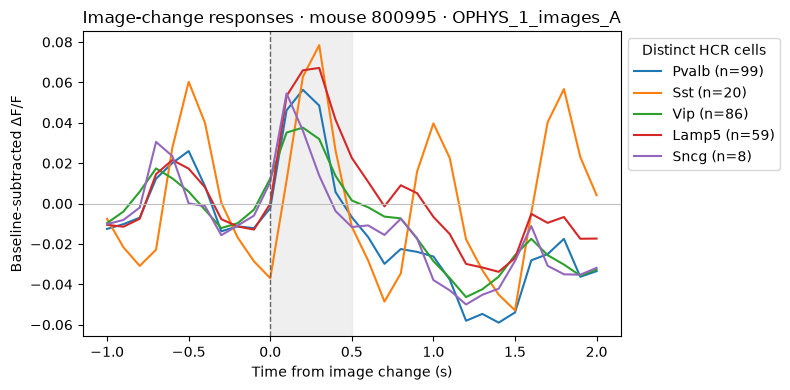

In [22]:
metrics, responses, event_counts = [], [], []
for plane, group in typed.groupby("plane"):
    series = nwb.processing[plane]["dff_timeseries"]["dff_timeseries"]
    time = np.asarray(series.timestamps[:])
    traces = np.asarray(series.data[:])[:, group.trace_col.to_numpy()]
    usable = np.isfinite(traces).any(axis=0)
    meta = group.loc[usable, ["unique_roi_id", "hcr_id", "subclass"]].set_index("unique_roi_id")
    traces = traces[:, usable]
    metrics.append(meta.assign(mean_dff=np.nanmean(traces, axis=0),
                               temporal_sd=np.nanstd(traces, axis=0)))
    windows = aligned_changes(traces, time, change_times)
    event_counts.append((plane, len(windows), len(meta), len(group) - len(meta)))
    if len(windows):
        baseline = np.nanmean(windows[:, rel_t < 0], axis=1, keepdims=True)
        roi_response = np.nanmean(windows - baseline, axis=0).T
        responses.append(meta.join(pd.DataFrame(roi_response, index=meta.index, columns=rel_t)))

display(pd.DataFrame(event_counts, columns=["plane", "complete_changes", "usable_typed_soma_rois",
                                           "all_missing_traces"]))
cell_keys = ["subclass", "hcr_id"]
activity = pd.concat(metrics).groupby(cell_keys).mean()
display(activity.groupby(level="subclass").agg(
    hcr_cells=("mean_dff", "count"), median_cell_mean_dff=("mean_dff", "median"),
    median_temporal_sd=("temporal_sd", "median")).reindex(order).round(3))

if responses:
    cell_response = pd.concat(responses).groupby(cell_keys).mean()
    early = cell_response.loc[:, (rel_t >= 0) & (rel_t < 0.5)].mean(axis=1)
    display(early.groupby(level="subclass").agg(["count", "mean", "median"])
            .reindex(order).rename(columns={"count": "HCR cells", "mean": "mean early ΔF/F",
                                            "median": "median early ΔF/F"}).round(3))
    fig, ax = plt.subplots(figsize=(8, 4))
    for subclass in order:
        if subclass in early.index.get_level_values("subclass"):
            curves = cell_response.xs(subclass)
            ax.plot(rel_t, curves.mean(), label=f"{subclass} (n={len(curves)})")
    ax.axhline(0, color="0.75", lw=0.8)
    ax.axvspan(0, 0.5, color="0.85", alpha=0.4)
    ax.axvline(0, color="0.4", ls="--", lw=1)
    ax.set(xlabel="Time from image change (s)", ylabel="Baseline-subtracted ΔF/F",
           title=f"Image-change responses · mouse {MOUSE} · {SESSION_TYPE}")
    ax.legend(title="Distinct HCR cells", bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()

## 17. What the worked session establishes

- **Identity.** For mouse 800995 on August 21, 2025, all 582 NWB trace columns have registration rows. The table references an earlier processing of the same acquisition. As a cross-check, we compared the nonzero pixels of each ROI mask at the same plane and row index in the two stores. All 582 pairs had identical spatial footprints. [Registration-source NWB metadata](https://aind-open-data.s3.us-west-2.amazonaws.com/multiplane-ophys_800995_2025-08-21_12-22-40_processed_2025-10-11_06-45-09/ophys_session_processed_%20%20%20%20%20%20%20%20%202025-10-11_08-10-49.nwb/.zmetadata)
- **Selection.** Of 537 soma ROIs, 332 matched an HCR row (61.8%). The match rate varied from 47.5% at 196 µm to 77.0% at 118 µm. The 287 soma ROIs with a named inhibitory subclass represent 272 distinct molecular cells. Counts range from eight Sncg cells to 99 Pvalb cells. Depth and subclass composition both matter when comparing responses.
- **Image changes.** All eight planes cover all 271 changes. Lamp5 had the largest mean early baseline-subtracted response (0.046 ΔF/F), followed by Pvalb (0.031), Sst (0.028), Vip (0.026), and Sncg (0.022). These are descriptive averages from one mouse on one familiar-image day.
- **Across learning.** The catalog and registration tables identify which stages and neurons overlap. A longitudinal comparison needs additional sessions with aligned stimuli, behavior, and activity. Use mouse plus HCR ID for molecular cells, audit repeated ROICaT tracks, and distinguish paired cells from changes in the sampled population. For trial-level work, the stimulus-to-trial link preserves outcome and reward timing alongside change onset.